# 4.3.3 RT bulk-derived signatures

Inés Sentís

Plot signatures found with DEG in bulk RNA samples of RTs. 

In [1]:
from pyprojroot import here
here = str(here())
import sys, os
sys.path.append(os.path.join(here,"utils"))

In [2]:
# basic pkgs
import os
import pandas as pd
import numpy as np
import glob
import pickle

# analysis pkgs
import scanpy as sc
import anndata as ad
import scipy as sp
import decoupler as dc
import gseapy as gp

# plotting pkgs
import matplotlib.pyplot as plt
from matplotlib_venn import venn2
from matplotlib import rcParams
import seaborn as sns

# own modules
from paths import *
from module import run_magic
from variables import resolutions, colors_donors

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', -1)

%load_ext autoreload
%autoreload 2
%config IPCompleter.greedy=True

/scratch_tmp/56412614/ipykernel_236995/2126204484.py:28: FutureWarning: Passing a negative integer is deprecated in version 1.0 and will not be supported in future version. Instead, use None to not limit the column width.
  pd.set_option('display.max_colwidth', -1)


In [3]:
def config_rcparams():
    commonFontsize = 12
    plt.rcParams['font.family'] = ['sans-serif']
    plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
    plt.rcParams['font.size'] = commonFontsize
    plt.rcParams['axes.labelsize'] = commonFontsize
    plt.rcParams['xtick.labelsize'] = commonFontsize
    plt.rcParams['ytick.labelsize'] = commonFontsize
    plt.rcParams['axes.titlesize'] = 14
    # plt.rcParams['text'] = commonFontsize
    plt.rcParams['svg.fonttype'] = 'none'
    plt.rcParams['mathtext.fontset'] = 'custom'
    plt.rcParams['mathtext.cal'] = 'DejaVu Sans'
    plt.rcParams['mathtext.rm'] = 'DejaVu Sans'
    plt.rcParams['axes.edgecolor'] = 'black'
    plt.rcParams['ytick.color'] = 'black'
    plt.rcParams['axes.linewidth'] = 0.7
    plt.rcParams['xtick.major.width'] = 0.7
    plt.rcParams['ytick.major.width'] = 0.7
    plt.rcParams['xtick.major.size'] = 3
    plt.rcParams['ytick.major.size'] = 3
    


config_rcparams()    

In [4]:
sc.logging.print_versions()
sc.set_figure_params(facecolor="white", figsize=(8, 8), 
                     scanpy=True, fontsize=16)
path_to_figures = os.path.join(here, "AVGUSTINOVA_01_06_09_15", "4-annotation", version, "plots_"+version)
sc.settings.figdir = path_to_figures
sc.settings.verbosity = 3

-----
anndata     0.9.2
scanpy      1.9.5
-----
NaiveDE                     NA
PIL                         10.0.0
SpatialDE                   NA
anyio                       NA
arrow                       1.2.3
asttokens                   NA
attr                        23.1.0
attrs                       23.1.0
babel                       2.12.1
backcall                    0.2.0
brotli                      1.1.0
certifi                     2023.07.22
cffi                        1.14.6
charset_normalizer          3.2.0
comm                        0.1.4
cycler                      0.10.0
cython_runtime              NA
dateutil                    2.8.2
debugpy                     1.8.0
decorator                   5.1.1
decoupler                   1.5.0
defusedxml                  0.7.1
deprecated                  1.2.14
exceptiongroup              1.1.3
executing                   1.2.0
fastjsonschema              NA
fqdn                        NA
future                      0.18.3
graphtoo

## Load data

Reading metadata info

In [5]:
df_info = pd.read_csv(os.path.join(here, "utils/info_samples.csv"))
df_info = df_info[(df_info["modality"] == "st") & (~df_info["quality"].isin(["Bad", "NM"]))]

Reading objects 

In [6]:
dict_samples = dict()

for sample in df_info['patient']:
    
    batch = df_info[df_info['patient'] == sample].reset_index()["subproject"][0]
    exec(open(os.path.join(here, batch,"st_analysis/misc/paths.py")).read())
    path_to_data = os.path.join(here, batch, "st_analysis/3-clustering", version, "py_objects_"+version)
    
    # read object
    adata = sc.read_h5ad(os.path.join(path_to_data, sample+'.h5ad'))
    adata.obs["patient"] = sample
    
    # read deconvolution results
    path_deconv = os.path.join(here, batch, "st_analysis/4-annotation", version, "R_objects_"+version, 
                                          "4.2.1-norm_weights_"+sample+"_l1.csv")
    
    if os.path.exists(path_deconv) == True: 
        df_weights = pd.read_csv(os.path.join(here, batch, "st_analysis/4-annotation", version, "R_objects_"+version, 
                                              "4.2.1-norm_weights_"+sample+"_l1.csv"), index_col=0)
        df_weights.columns = "deconv_"+df_weights.columns
        adata.obs = pd.merge(adata.obs, df_weights, how='left', left_index=True, right_index=True)

    dict_samples[sample] = adata

In [7]:
df_sign = pd.read_csv(os.path.join(here, "external_data/bulk_rhab_signatures/rt_general.csv"))

df_sign["source"] = "RT SIG"
df_sign["target"] = df_sign["gene"]
df_sign["weight"] = df_sign["meanlog2fc"]

## Run signatures per sample

In [ ]:
for id, ann in dict_samples.items():
    print(id)
    dc.run_mlm(mat=dict_samples[id], net=df_sign, source='source', target='target', weight='weight', verbose=True)
    
    dict_samples[id].obsm['sign_mlm_estimate'] = dict_samples[id].obsm['mlm_estimate'].copy()
    dict_samples[id].obsm['sign_mlm_pvals'] = dict_samples[id].obsm['mlm_pvals'].copy()

In [10]:
deconv_patients = ['p10','p5','p8','p4','p9','p7','p2','p6','p13','p14']
for id in deconv_patients:
    dict_samples[id].obs = pd.merge(
        dict_samples[id].obs,Ω
        dict_samples[id].obsm['sign_mlm_estimate'], 
        how="left", left_index=True, right_index=True
    )

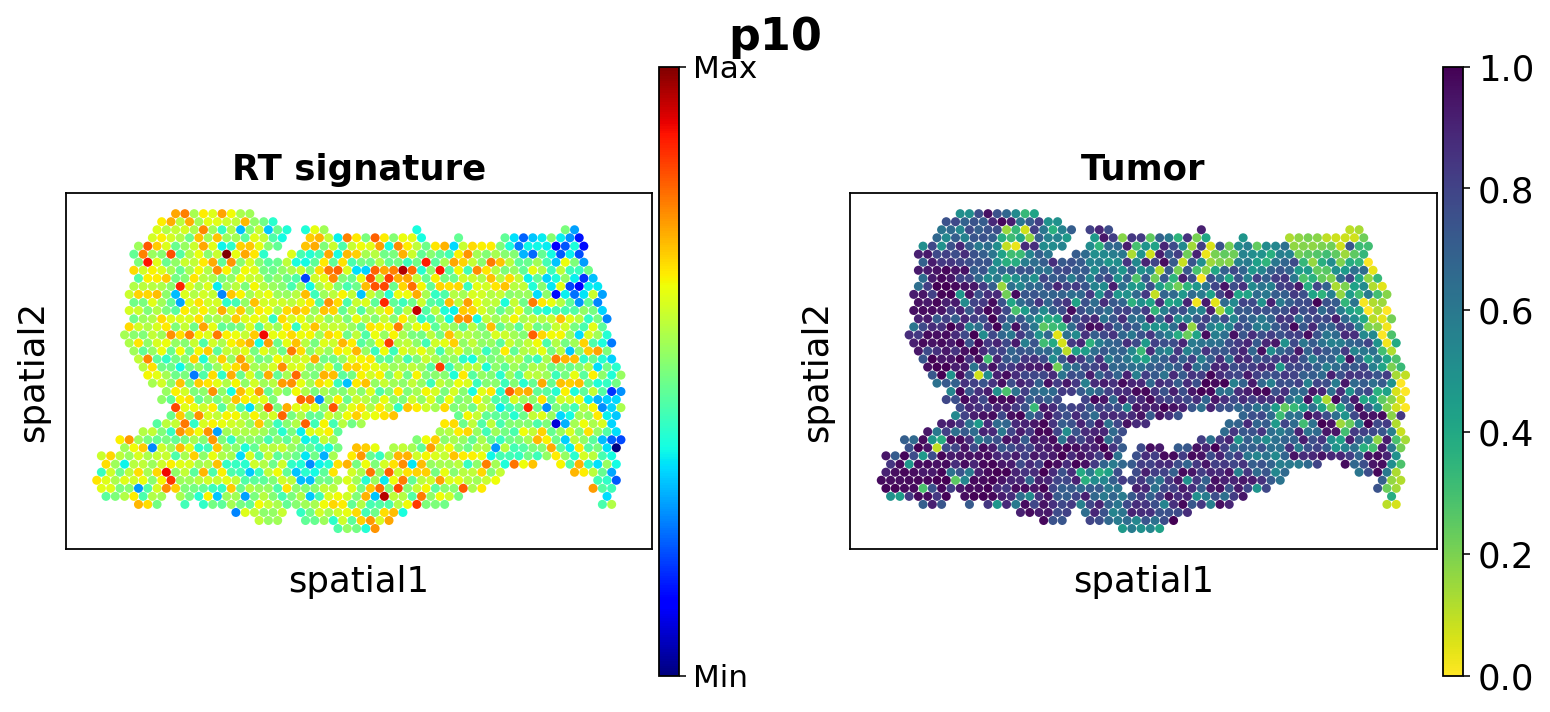

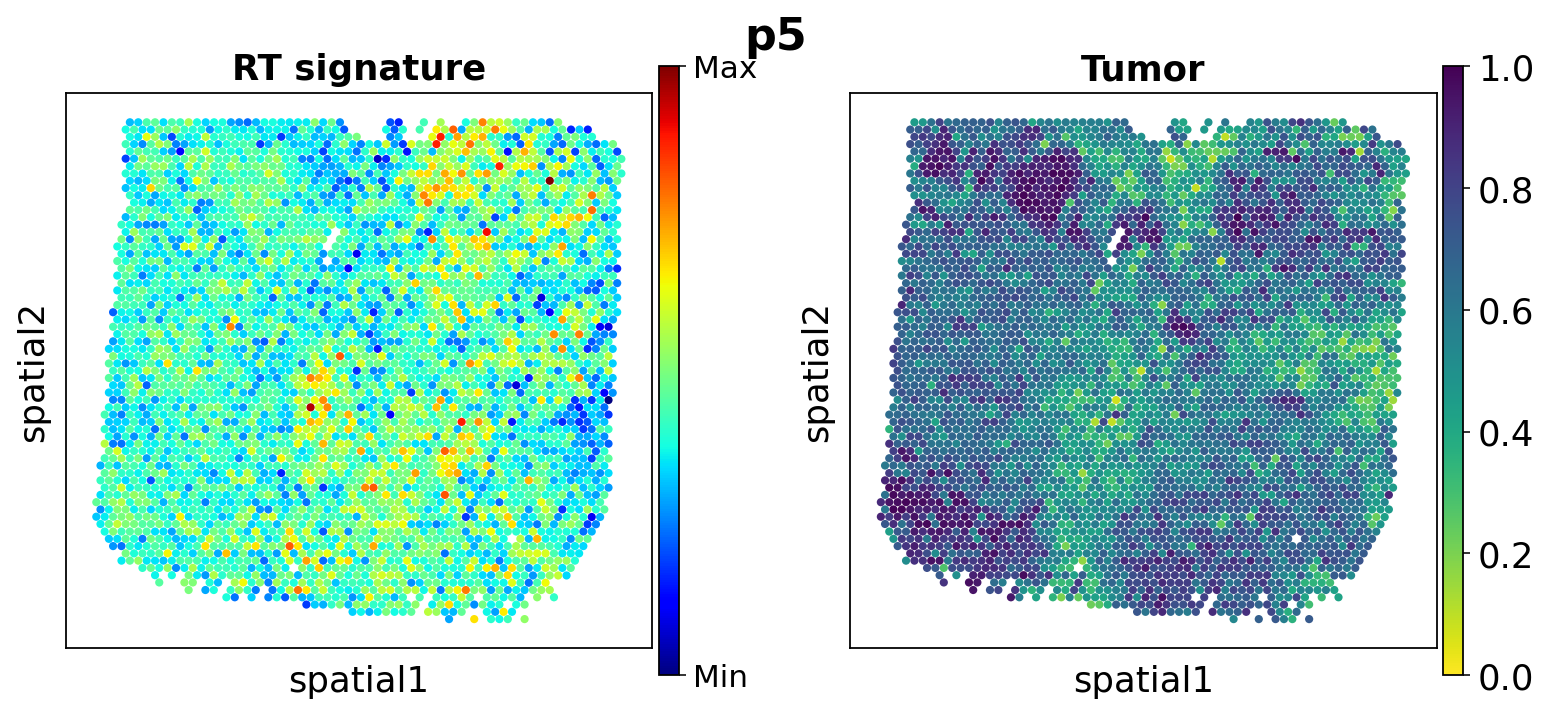

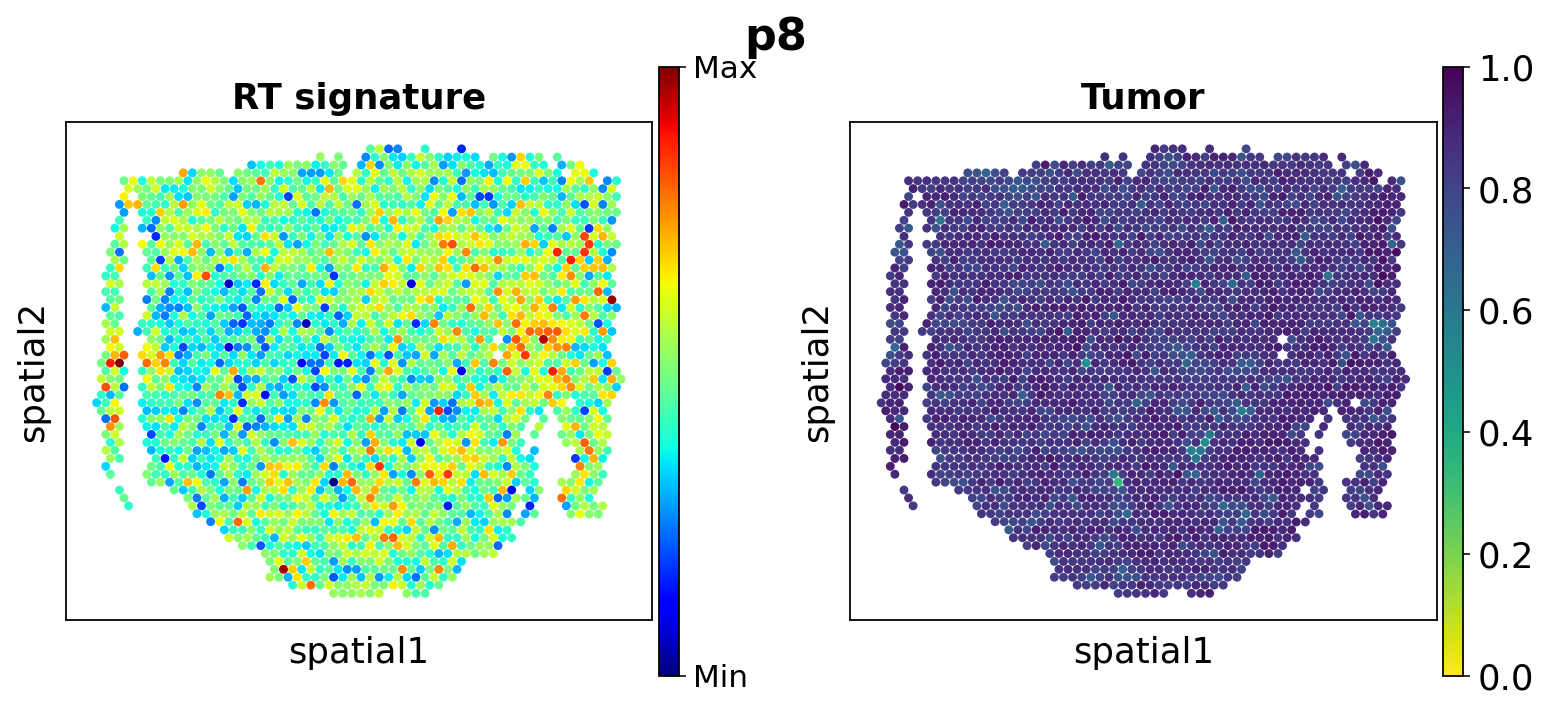

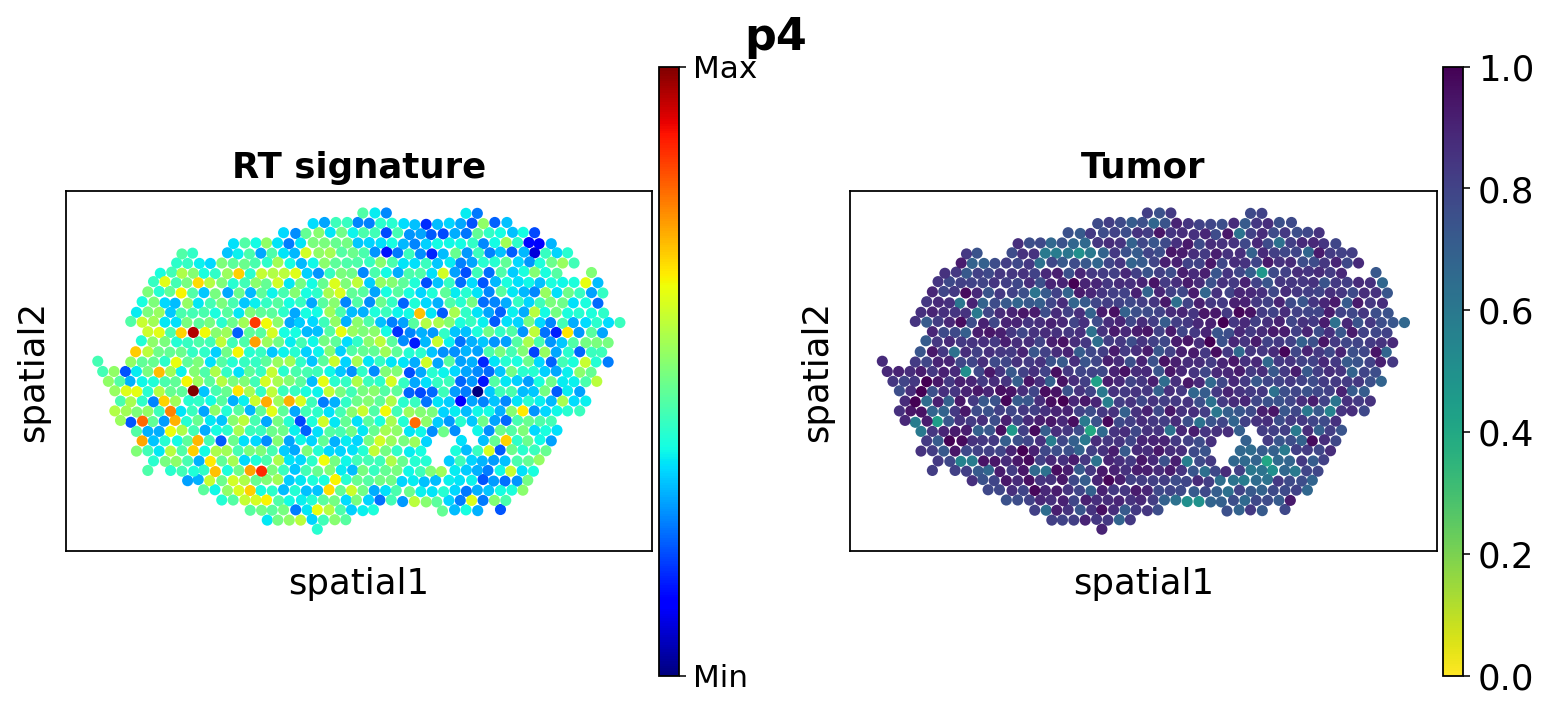

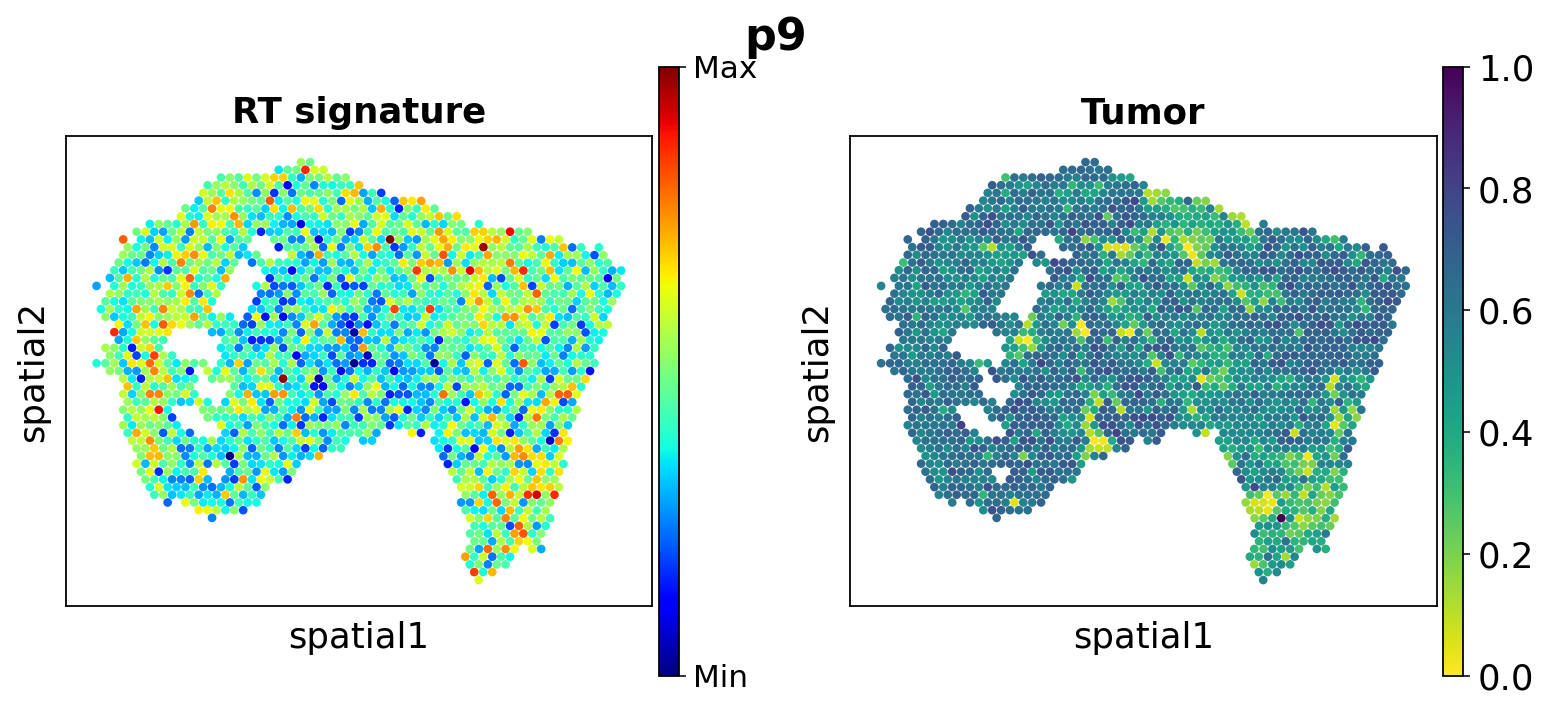

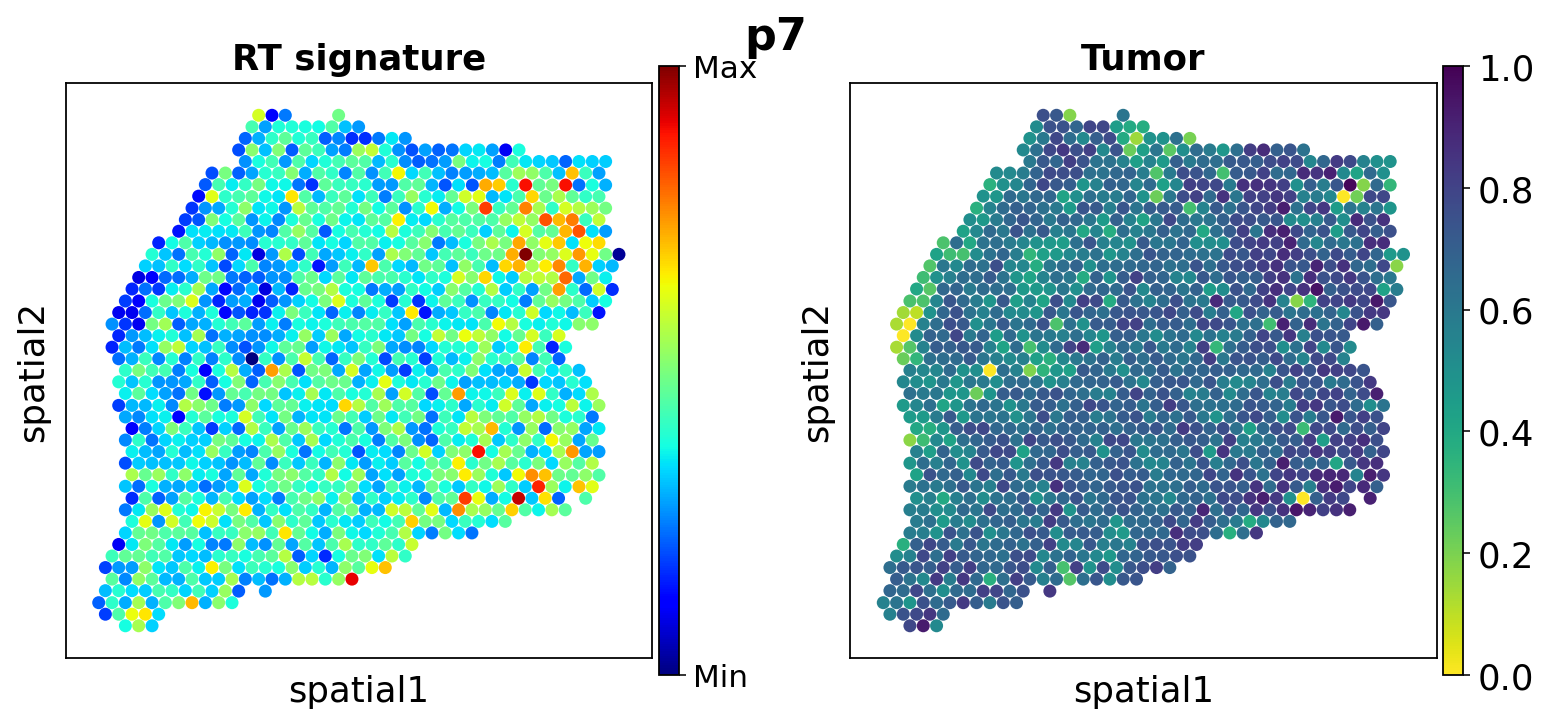

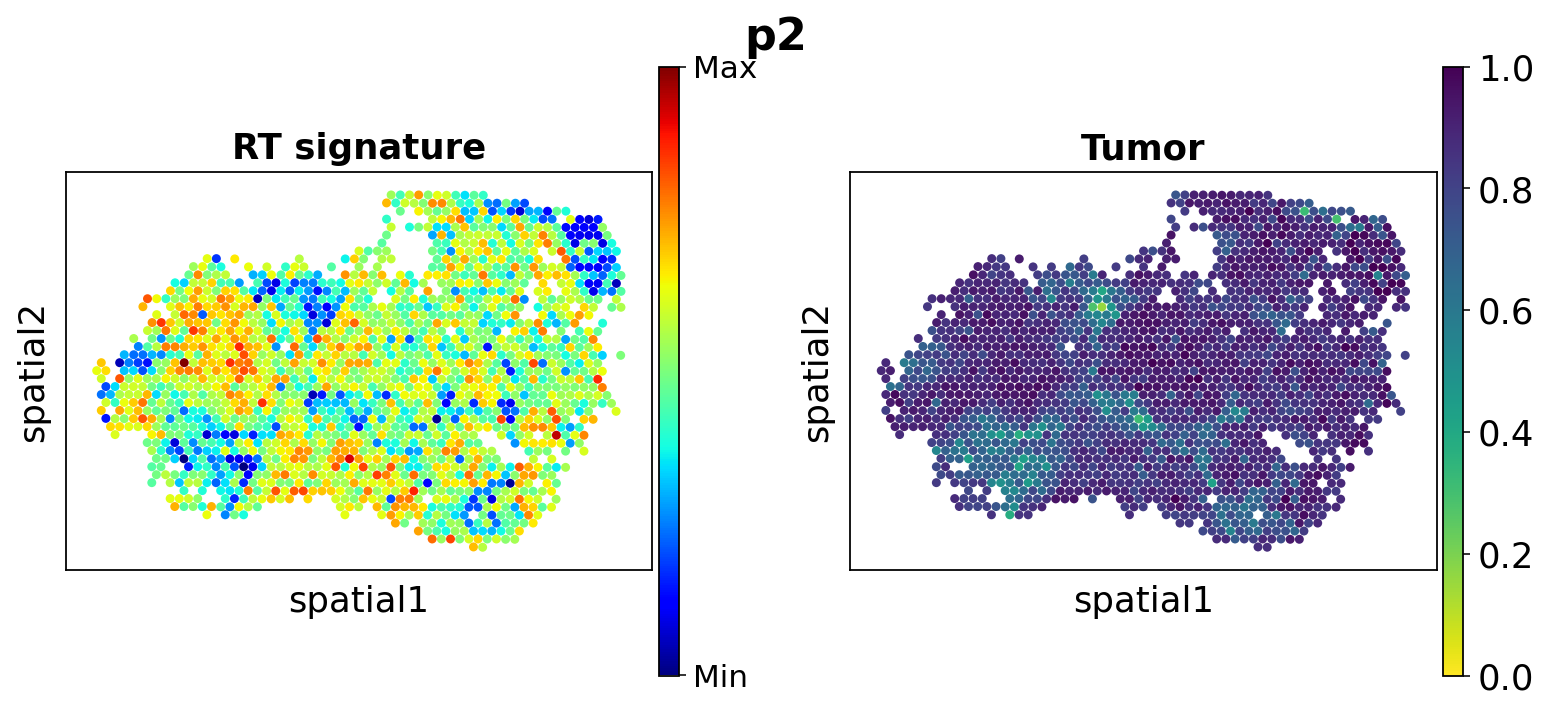

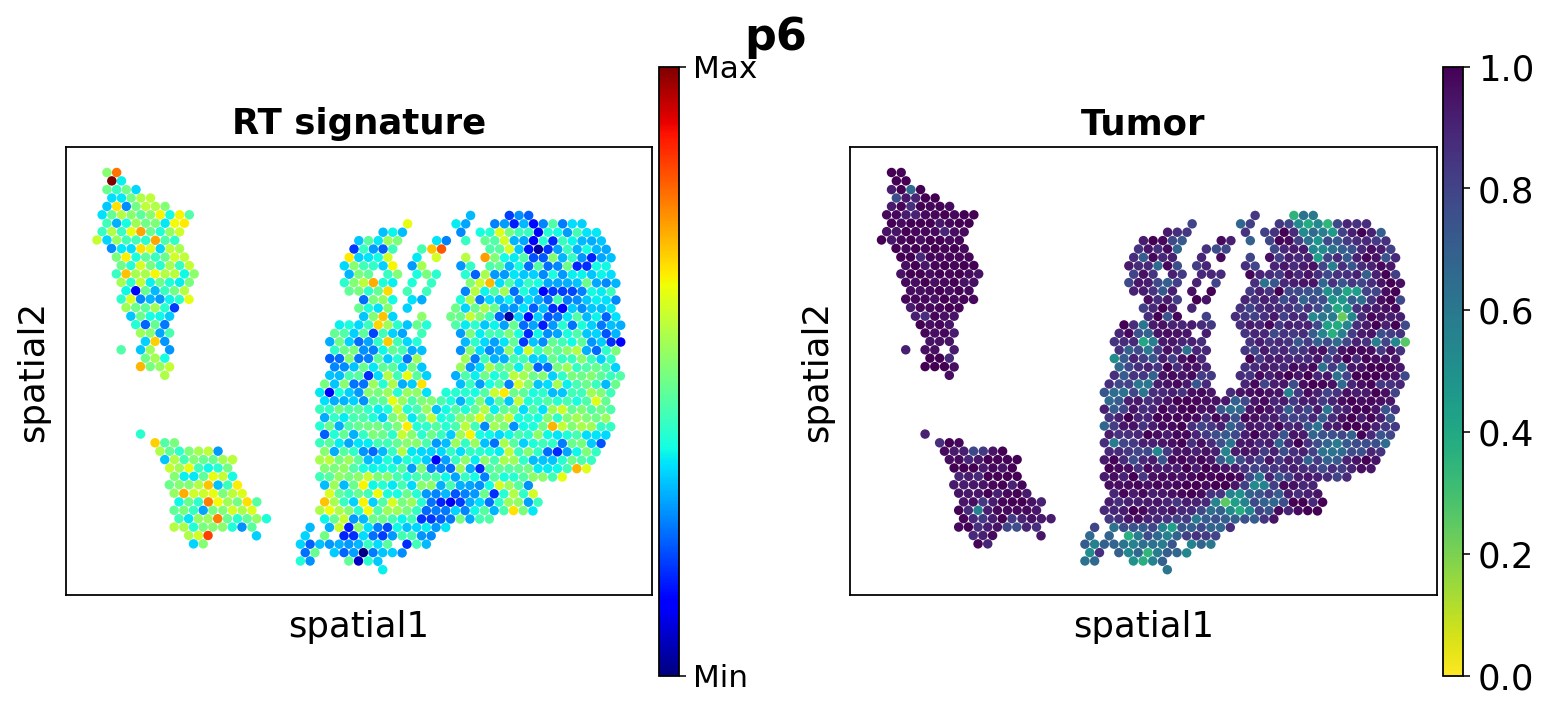

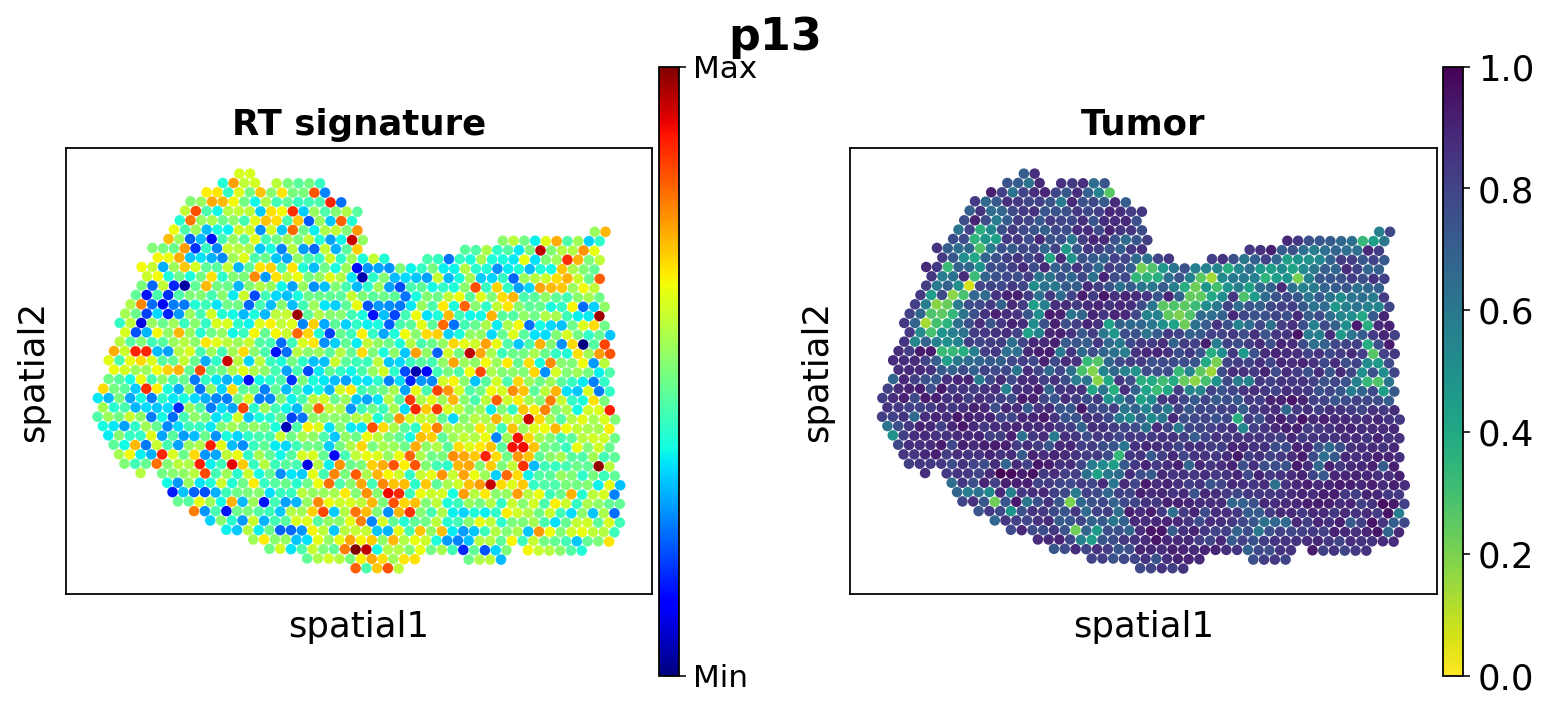

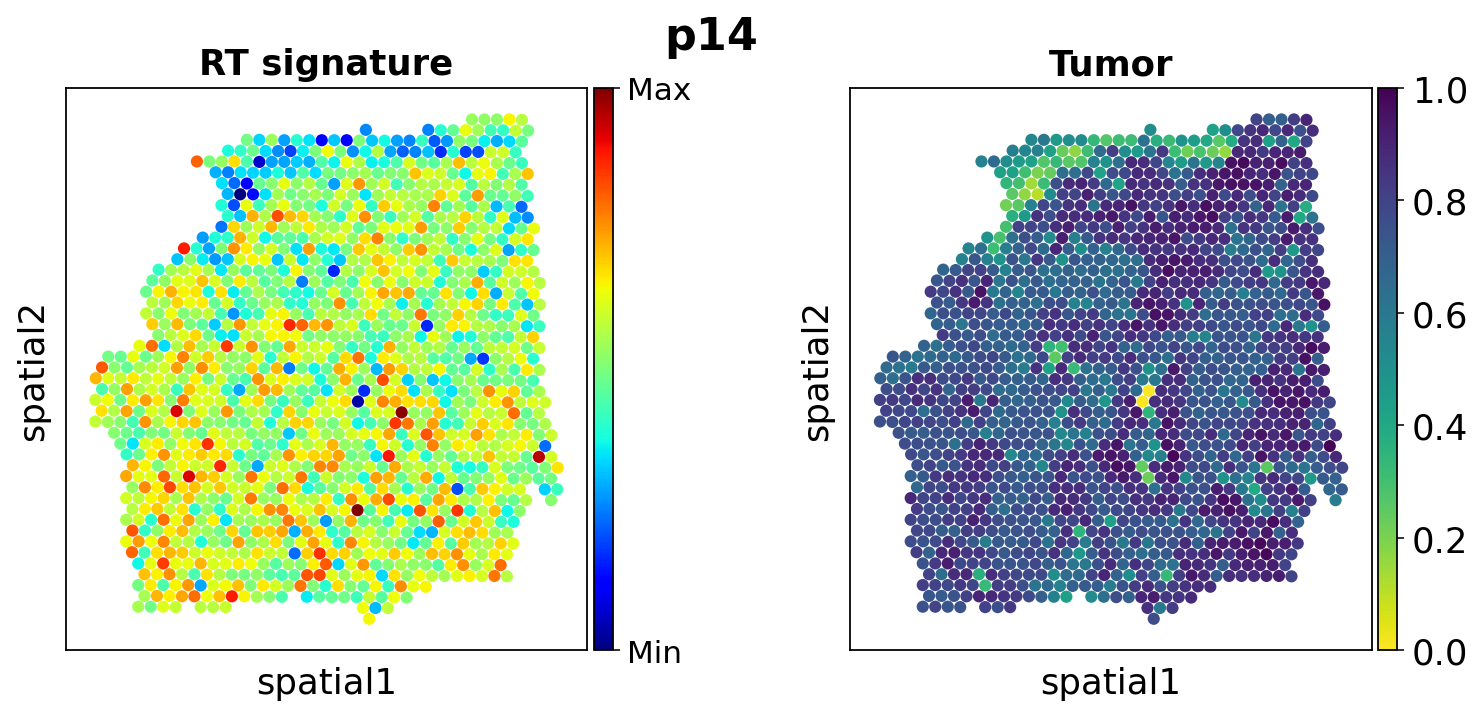

In [11]:
sc.set_figure_params(fontsize=16)

for id in deconv_patients:
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    plt.subplots_adjust(wspace=0.05)
    
    colors_to_plot = ['RT SIG', "deconv_Tumor"]
    cmaps_to_use = ['jet', 'viridis_r'] 
    custom_titles = ['RT signature', 'Tumor'] 
    
    for ax, color_key, cmap_name, title in zip(axes, colors_to_plot, cmaps_to_use, custom_titles):
        extra_params = {}
        if color_key == "deconv_Tumor":
            extra_params['vmin'] = 0
            extra_params['vmax'] = 1
            
        sc.pl.spatial(
            dict_samples[id], 
            color=color_key, 
            cmap=cmap_name, 
            ax=ax, 
            show=False,
            size=1.5,
            img_key = None,
            **extra_params
        )
        if color_key == 'RT SIG':
            cbar_ax = fig.axes[-1]
            vmin, vmax = ax.collections[0].get_clim()
            cbar_ax.set_yticks([vmin, vmax])
            cbar_ax.set_yticklabels(['Min', 'Max'], fontsize=14)
            cbar_ax.set_ylabel('')
            
        ax.set_title(title, fontsize=16,fontweight='bold')

    plt.suptitle(id, fontsize=20, y=0.9,fontweight='bold')
    plt.tight_layout()
    
    # Save/Show
    plt.savefig(os.path.join(path_to_figures, f"spatial_{id}_sig.svg"), format='svg', bbox_inches='tight')
    plt.show()

In [12]:
# Merge the AnnData objects
merged_adata = ad.concat(dict_samples.values(), join='outer')

# remove empty genes
sc.pp.filter_genes(merged_adata, min_cells=1)

# Normalize the merged AnnData object
merged_adata.X = merged_adata.layers['counts'].copy()
sc.pp.normalize_total(merged_adata, target_sum=1e4)
sc.pp.log1p(merged_adata)
merged_adata.layers['normalized'] = merged_adata.X.copy()

filtered out 12 genes that are detected in less than 1 cells
normalizing counts per cell
    finished (0:00:00)


In [13]:
path_to_data = os.path.join(here,"AVGUSTINOVA_01_06_09_15")
counts_df = pd.DataFrame(
                merged_adata.layers['counts'].toarray(),
                index=merged_adata.obs_names,
                columns=merged_adata.var_names
            )
counts_df = counts_df.astype(int)

data_df = pd.DataFrame(
                merged_adata.X.toarray(),
                index=merged_adata.obs_names,
                columns=merged_adata.var_names
            ) 
data_df = data_df.astype(float)

metadata_df = merged_adata.obs
            
# Save to CSV
counts_df.to_csv(os.path.join(path_to_data,"4.3.3-counts_matrix_tumor.csv"))
data_df.to_csv(os.path.join(path_to_data,"4.3.3-data_matrix_tumor.csv"))
metadata_df.to_csv(os.path.join(path_to_data,"4.3.3-metadata_tumor.csv"))